# 07 — Uncertainty, frozen evaluation, and recommendation

Choose the candidate by primary-scenario profit on selection, quantify development uncertainty, and freeze its artifact and policy **before** reading evaluation labels. The [freeze manifest](../config/candidate-freeze.json) records raw Random Forest, all 30 inputs including Time, the identity score mapping, and the fixed 0.20 threshold for positive amounts. No post-hoc calibrator was adopted.

Whole V1–V28/Amount pattern groups are sampled with replacement, using the same draws for every compared policy. The 2,000 bootstrap draws (seed 42) use the sampled payment count as their denominator. Percentile 95% intervals condition on these fitted models and observed groups. They exclude training and repeated model-selection uncertainty; exact-pattern groups do not identify real cards or customers.

Running the cell below reuses the cached final result after checking its freeze and lineage. It does not retrain or repeatedly score evaluation. Full-dataset label-aware EDA preceded this protocol, so evaluation is not an untouched analytical holdout.

In [1]:
from pathlib import Path
import json, os, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
env = os.environ.copy()
env.update(OPENBLAS_NUM_THREADS="1", OMP_NUM_THREADS="1", MLFLOW_DISABLE_AGENT_HINT="1")
run = subprocess.run([sys.executable, str(root / "scripts/run_final_evaluation.py")], cwd=root, env=env, capture_output=True, text=True)
print(run.stdout)
if run.returncode:
    print(run.stderr)
run.check_returncode()

Using cached final evaluation; no new scoring or model selection performed.
               name  average_precision  brier_score  simulated_profit_per_1000  fraud_canceled_recall  legitimate_canceled
  random_forest_raw           0.794050     0.000522               22573.897035               0.760563                   10
        approve_all           0.001663     0.001660               22461.398440               0.000000                    0
        amount_rule           0.002049          NaN               17420.222162               0.028169                  477
logistic_regression           0.663190     0.000816               22544.910995               0.605634                   13
        candidate          comparator  profit_difference_per_1000  lower_95  upper_95   conclusion
random_forest_raw         approve_all                     112.499    42.072   201.260     positive
random_forest_raw         amount_rule                    5153.675  4566.818  5752.084     positive
random_fores

In [2]:
freeze = json.loads((root / "config/candidate-freeze.json").read_text())
selection = json.loads((root / "reports/selection-uncertainty.json").read_text())
report = json.loads((root / "reports/final-evaluation.json").read_text())
print("Frozen candidate:", freeze["candidate"]["name"], "mapping:", freeze["candidate"]["mapping"])
print("Freeze UTC:", freeze["frozen_at_utc"], "| Evaluation UTC:", report["metadata"]["scored_at_utc"])
print("Selection contains", selection["rows"], "payments and", selection["frauds"], "frauds.")
display(pd.DataFrame(selection["paired_differences"]).round(3))

Frozen candidate: random_forest_raw mapping: identity
Freeze UTC: 2026-10-19T00:18:15.306575+00:00 | Evaluation UTC: 2026-10-19T00:18:27.895208+00:00
Selection contains 42632 payments and 76 frauds.


,candidate,comparator,profit_difference_per_1000,lower_95,upper_95,conclusion
0,random_forest_raw,amount_rule,4542.168,4021.372,5111.631,positive
1,random_forest_raw,approve_all,100.479,-299.614,365.589,inconclusive
2,random_forest_raw,logistic_regression,29.580,4.995,59.859,positive
3,random_forest_raw,random_forest_isotonic,38.359,-3.144,100.439,inconclusive
4,random_forest_raw,lightgbm_raw,12.081,-12.569,50.572,inconclusive


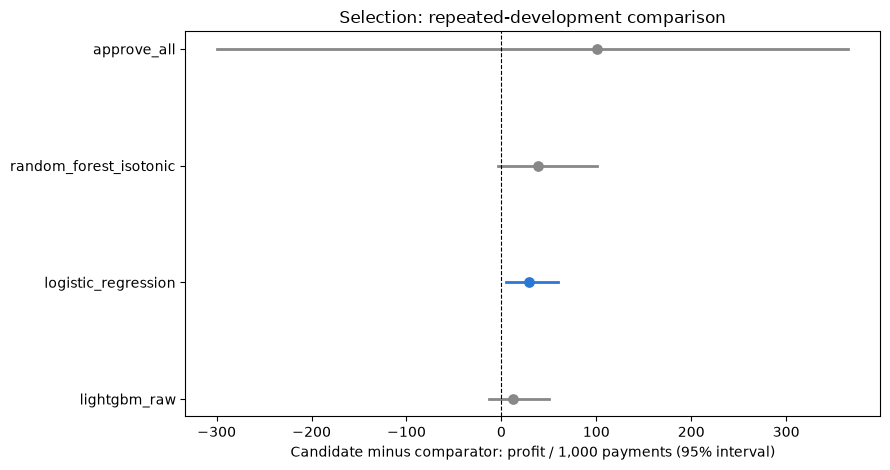

In [3]:
def plot_intervals(table, title, path):
    data = table.sort_values("profit_difference_per_1000")
    fig, ax = plt.subplots(figsize=(9, 4.8))
    for position, row in enumerate(data.itertuples()):
        color = "#2a78d6" if row.lower_95 > 0 else "#888888"
        ax.plot([row.lower_95, row.upper_95], [position, position], color=color, linewidth=2)
        ax.scatter(row.profit_difference_per_1000, position, color=color, s=45)
    ax.set_yticks(range(len(data)), data.comparator)
    ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set(title=title, xlabel="Candidate minus comparator: profit / 1,000 payments (95% interval)")
    fig.tight_layout()
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()
# The amount rule has a much larger gap; its interval is retained in the table.
selection_intervals = pd.DataFrame(selection["paired_differences"])
plot_intervals(selection_intervals.loc[selection_intervals.comparator.ne("amount_rule")],
               "Selection: repeated-development comparison", root / "reports/figures/selection-profit-uncertainty.png")

## Final evaluation on all reserved payments

Selection's primary interval crossed zero. The candidate was still frozen as the observed profit leader, without a superiority or production claim. Evaluation scores that fixed candidate against approve-all, the training-p99 amount rule, and the fixed logistic reference. No LightGBM or calibration-method search occurs on evaluation.

,name,rows,frauds,average_precision,roc_auc,brier_score,simulated_total_profit,simulated_profit_per_1000,profit_pct_of_maximum,frauds_canceled,legitimate_canceled
0,random_forest_raw,42694,71,0.794050,0.946960,0.000522,963769.960,22573.897035,99.545094,54,10
1,approve_all,42694,71,0.001663,0.500000,0.001660,958966.945,22461.398440,99.049004,0,0
2,amount_rule,42694,71,0.002049,0.426674,NaN,743738.965,17420.222162,76.818710,2,477
3,logistic_regression,42694,71,0.663190,0.970951,0.000816,962532.430,22544.910995,99.417273,43,13


,candidate,comparator,profit_difference_per_1000,lower_95,upper_95,conclusion
0,random_forest_raw,approve_all,112.499,42.072,201.260,positive
1,random_forest_raw,amount_rule,5153.675,4566.818,5752.084,positive
2,random_forest_raw,logistic_regression,28.986,-4.377,86.461,inconclusive


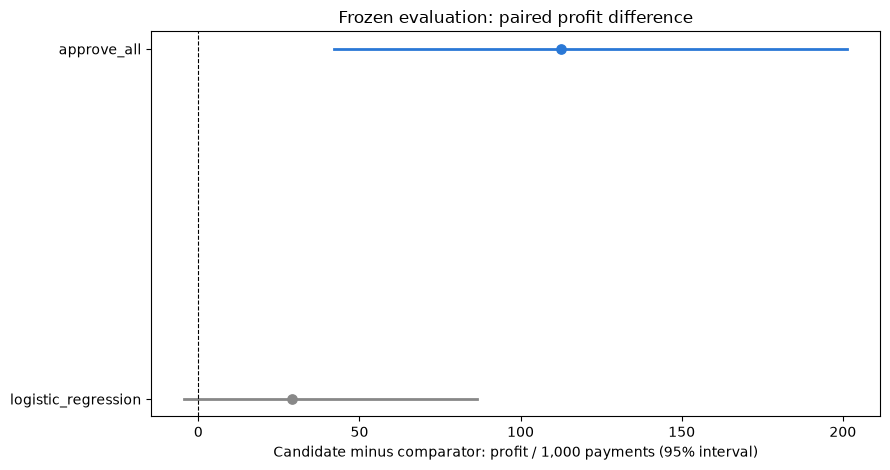

In [4]:
metrics = pd.DataFrame(report["results"])
display(metrics[["name", "rows", "frauds", "average_precision", "roc_auc", "brier_score", "simulated_total_profit", "simulated_profit_per_1000", "profit_pct_of_maximum", "frauds_canceled", "legitimate_canceled"]].round(6))
evaluation_intervals = pd.DataFrame(report["uncertainty"]["paired_differences"])
display(evaluation_intervals.round(3))
plot_intervals(evaluation_intervals.loc[evaluation_intervals.comparator.ne("amount_rule")],
               "Frozen evaluation: paired profit difference", root / "reports/figures/final-profit-uncertainty.png")

## Fixed operating-point diagnostic and probability reliability

The 0.1% false-positive diagnostic uses a score threshold chosen on **selection** and stored in the freeze; evaluation only measures the resulting recall and false-positive rate. It is a score-only ranking diagnostic, including zero-amount payments. The economic 0.20 policy separately approves zero amounts because both actions have zero modeled payoff. Scores remain uncalibrated; these final reliability bins describe them without changing the model.

In [5]:
print(report["frozen_fpr_diagnostic"])
print("Opportunity-loss concentration:", report["opportunity_loss_concentration"])
predictions = pd.read_csv(root / report["predictions"]["path"])
candidate_predictions = predictions.loc[predictions.model.eq(report["metadata"]["candidate"])].copy()
bands = pd.cut(candidate_predictions.score, bins=[0, 0.0001, 0.001, 0.01, 0.05, 0.2, 0.5, 1.0000001], include_lowest=True)
reliability = candidate_predictions.groupby(bands, observed=True).agg(payments=("Class", "size"), frauds=("Class", "sum"), mean_score=("score", "mean"))
reliability["observed_fraud_rate"] = reliability.frauds / reliability.payments
display(reliability.round(5))

{'threshold': 0.30541666666666667, 'predict_none': False, 'selection_target_fpr': 0.001, 'comparison': 'score >= threshold', 'evaluation_fraud_recall': 0.7746478873239436, 'evaluation_realized_fpr': 0.00018769209112451025}
Opportunity-loss concentration: {'largest_error': 2125.87, 'top_5_loss_share_pct': 91.78856499976727}


,payments,frauds,mean_score,observed_fraud_rate
score,,,,
"(-0.001, 0.0001]",40064,7,0.00000,0.00017
"(0.0001, 0.001]",31,0,0.00097,0.00000
"(0.001, 0.01]",2172,3,0.00367,0.00138
"(0.01, 0.05]",335,4,0.01942,0.01194
"(0.05, 0.2]",26,1,0.09540,0.03846
"(0.2, 0.5]",11,5,0.37140,0.45455
"(0.5, 1.0]",55,51,0.83670,0.92727


## Economic sensitivity

All nine margin/fraud-loss combinations and both sensitivity rules were recorded before evaluation. The first holds the original 0.20 actions fixed and only changes payoffs. The second applies the algebraic threshold `margin / (margin + fraud loss)` to the same frozen scores. Each cell is candidate profit minus approve-all per 1,000 payments. These are descriptive point estimates, not nine independently confirmed effects; no scenario is selected to replace the primary 25%/100% assumptions.

,margin_fraction,fraud_loss_fraction,scenario_threshold,primary_scenario,frozen_actions_profit_difference_per_1000,scenario_threshold_profit_difference_per_1000,scenario_cancellation_rate
0,0.10,0.5,0.1667,False,57.0404,57.0357,0.0015
1,0.10,1.0,0.0909,False,117.2454,108.4857,0.0018
2,0.10,1.5,0.0625,False,177.4503,118.3788,0.0019
3,0.25,0.5,0.3333,False,52.2936,54.7414,0.0014
4,0.25,1.0,0.2000,True,112.4986,112.4986,0.0015
5,0.25,1.5,0.1429,False,172.7035,172.1604,0.0016
6,0.40,0.5,0.4444,False,47.5469,56.6506,0.0013
7,0.40,1.0,0.2857,False,107.7518,107.8442,0.0015
8,0.40,1.5,0.2105,False,167.9568,167.9568,0.0015


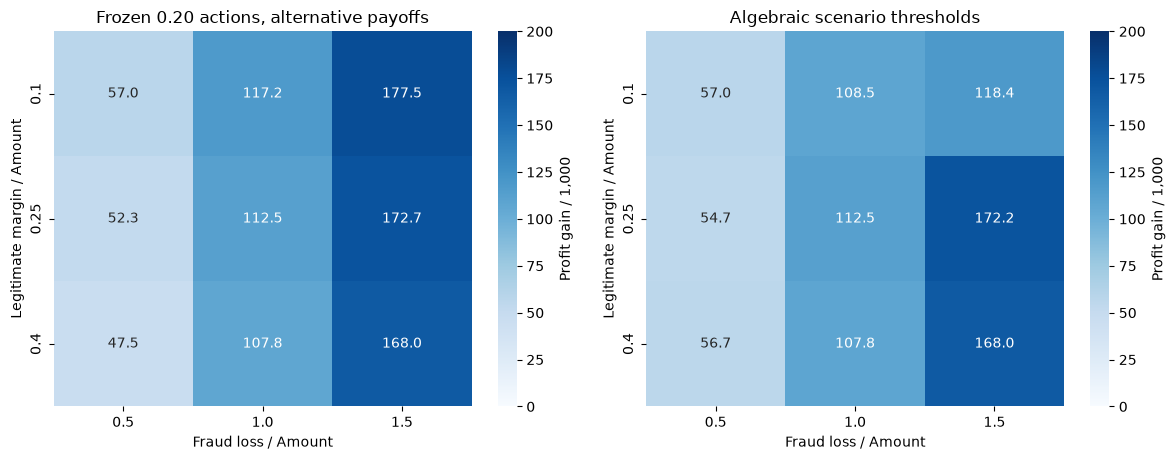

In [6]:
sensitivity = pd.DataFrame(report["sensitivity"])
display(sensitivity.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
for ax, field, title in zip(axes,
    ["frozen_actions_profit_difference_per_1000", "scenario_threshold_profit_difference_per_1000"],
    ["Frozen 0.20 actions, alternative payoffs", "Algebraic scenario thresholds"]):
    grid = sensitivity.pivot(index="margin_fraction", columns="fraud_loss_fraction", values=field)
    sns.heatmap(grid, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=200, ax=ax, cbar_kws={"label": "Profit gain / 1,000"})
    ax.set(title=title, xlabel="Fraud loss / Amount", ylabel="Legitimate margin / Amount")
fig.tight_layout()
fig.savefig(root / "reports/figures/final-economic-sensitivity.png", dpi=160, bbox_inches="tight")
plt.show()

**Recommendation:** The frozen Random Forest supports a positive modeled gain over approve-all on this evaluation population. Its profit advantage over logistic regression is inconclusive. Proceed with a versioned offline/demo prototype; keep the raw-score calibration limitation and prior analytical exposure explicit. This two-day source cannot establish production impact or future-period performance. Final evaluation is now consumed: changes influenced by these results must use it as a regression benchmark, and a fresh confirmation needs new labeled data. No production champion is promoted here.